# Toy four-zone model

A small transport model you can check by hand. Every number is made up, so nothing here is Salisbury data.

The notebook is built in **seven levels**, 0 to 6. Each level keeps everything from the level before and adds one idea. You can stop at any level and still have a working model.

| Level | What it adds | Parts |
|---|---|---|
| 0 | From real places to a map of zones and roads | Steps 1 to 6 |
| 1 | Where work trips go, using travel time only | A to E |
| 2 | A second kind of trip: shopping and leisure | F |
| 3 | Turning money, walking and waiting into minutes | G |
| 4 | Choosing between car and bus | H to I |
| 5 | Putting cars on the roads, and traffic jams | J to K |
| 6 | Checking the model against counts | L to N |

**Units:** trips per hour (trips/h), minutes (min), vehicles per hour (veh/h), pounds (£).

**Made-up numbers.** Values marked *placeholder* are invented. Each one is to be replaced with a sourced value, and the source logged in `docs/methodology.md`.

**TAG references.** Each decision has a one-line TAG reference. The full quotes, with a status for each decision, are in `docs/methodology.md`.

## Setup

Three tools: `numpy` does the matrix arithmetic, `pandas` makes tables readable, and `matplotlib` draws the charts.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 100)

ZONES = ["A", "B", "C", "D"]
n = len(ZONES)
idx = {z: k for k, z in enumerate(ZONES)}

# Zone centroids for every map, defined once. Made-up layout in km.
POS = {"A": (2, 4.5), "B": (6, 4.5), "C": (6, 1.5), "D": (2, 1.5)}

### A map to keep your place

The model has four steps, run one after another. This picture comes back at the top of each level with the current step filled in, so you can see where you are.

In [2]:
STAGES = ["1. Trip generation\nhow many trips",
          "2. Trip distribution\nwhere they go",
          "3. Mode choice\ncar or bus",
          "4. Assignment\nwhich roads"]

def draw_stages(active=(), note=None, feedback=False, title=None):
    """The four steps, with the current one(s) filled in. active is a set of step numbers."""
    fig, ax = plt.subplots(figsize=(10, 3.1 if feedback else 2.3))
    y = 1.0 if feedback else 0.4
    for k, text in enumerate(STAGES):
        on = (k + 1) in active
        x = k * 2.6
        ax.add_patch(FancyBboxPatch((x, y), 2.1, 1.2, boxstyle="round,pad=0.05",
                                    facecolor="#cfe0fb" if on else "#f5f6f8",
                                    edgecolor="tab:blue" if on else "0.75",
                                    linewidth=2.0 if on else 1.0))
        ax.text(x + 1.05, y + 0.6, text, ha="center", va="center", fontsize=9,
                weight="bold" if on else "normal", color="0.1" if on else "0.5")
        if k < len(STAGES) - 1:
            ax.annotate("", xy=(x + 2.5, y + 0.6), xytext=(x + 2.15, y + 0.6),
                        arrowprops=dict(arrowstyle="->", color="0.5"))
    if feedback:
        # The loop a fuller model would close: congested times back into distribution.
        x_from, x_to = 3 * 2.6 + 1.05, 1 * 2.6 + 1.05
        ax.plot([x_from, x_from], [y, 0.55], color="tab:red", linestyle="--")
        ax.plot([x_from, x_to], [0.55, 0.55], color="tab:red", linestyle="--")
        ax.annotate("", xy=(x_to, y), xytext=(x_to, 0.55),
                    arrowprops=dict(arrowstyle="->", color="tab:red", linestyle="--"))
        ax.text((x_from + x_to) / 2, 0.25, "not in this notebook: congested times do not feed back",
                ha="center", va="center", fontsize=8.5, color="tab:red")
    if note:
        ax.text(5.0, y + 1.45, note, ha="center", va="bottom", fontsize=9, color="0.3")
    ax.set_xlim(-0.2, 10.4)
    ax.set_ylim(0.1, y + 1.95 if note else y + 1.4)
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.show()

# Level 0: from the real world to a network

This level has **no model numbers**. It shows how real places become zones, points and roads, and says what each step throws away.

**Why:** a model is only as good as the simplifications behind it. Write each one down and you can check it and change it.

### Step 1: the real world

The real world is a set of **places** of different shapes and sizes: homes, a workplace, shops and a school. Nothing in it is a neat square or a single point. A model cannot hold every place, so the next steps simplify it.

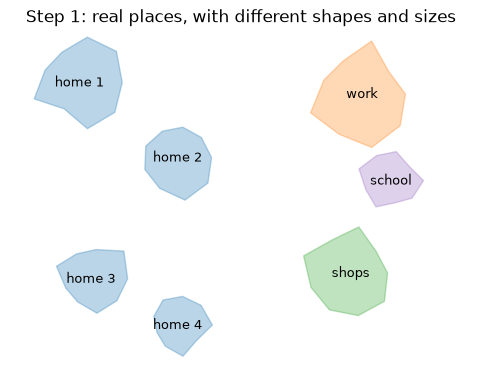

In [3]:
# Made-up real places as irregular shapes, on the same 0-8 by 0-6 frame as every later map.
rng = np.random.default_rng(7)   # fixed seed, so the shapes are the same on every run

def blob(cx, cy, r, m=9):
    """An irregular outline: a circle with each point pushed in or out a little."""
    ang = np.linspace(0, 2 * np.pi, m, endpoint=False)
    rad = r * (1 + 0.25 * rng.uniform(-1, 1, m))
    return np.column_stack([cx + rad * np.cos(ang), cy + rad * np.sin(ang)])

# name: (kind, centre x, centre y, size in km). The kind sets the colour.
PLACES = {
    "home 1": ("home", 1.2, 5.1, 0.7),
    "home 2": ("home", 2.9, 3.8, 0.6),
    "home 3": ("home", 1.4, 1.7, 0.6),
    "home 4": ("home", 2.9, 0.9, 0.5),
    "work":   ("work", 6.1, 4.9, 0.8),
    "school": ("school", 6.6, 3.4, 0.5),
    "shops":  ("shop", 5.9, 1.8, 0.7),
}
COLOUR = {"home": "tab:blue", "work": "tab:orange", "school": "tab:purple", "shop": "tab:green"}
SHAPE = {name: blob(cx, cy, r) for name, (kind, cx, cy, r) in PLACES.items()}

def draw_places(ax, alpha=0.3):
    for name, (kind, cx, cy, r) in PLACES.items():
        ax.add_patch(Polygon(SHAPE[name], closed=True, facecolor=COLOUR[kind],
                             alpha=alpha, edgecolor=COLOUR[kind]))
        ax.text(cx, cy, name, ha="center", va="center", fontsize=9)

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.3)
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 1: real places, with different shapes and sizes")
plt.show()

### Step 2: why people travel

People travel because the things they want to do are in different places. Someone lives in one place, works in another and shops in a third. A **trip** is one move from one activity to another, and it has a **purpose**: work, shopping, school.

Each numbered arrow below is one trip. Level 1 starts with work trips; Level 2 adds shopping and leisure.

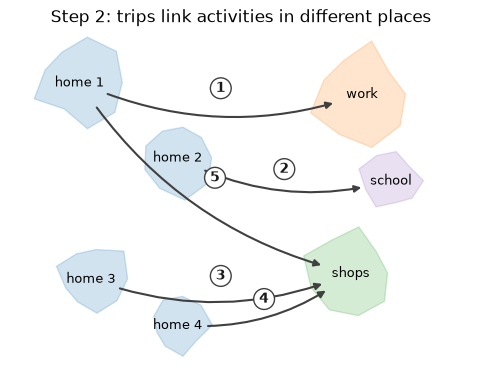

,trip,from,to,purpose
0,1,home 1,work,work
1,2,home 2,school,school
2,3,home 3,shops,shopping
3,4,home 4,shops,shopping
4,5,home 1,shops,shopping


In [4]:
# The same places, joined by numbered arrows: one arrow per trip.
TRIPS = [
    ("home 1", "work", "work"),
    ("home 2", "school", "school"),
    ("home 3", "shops", "shopping"),
    ("home 4", "shops", "shopping"),
    ("home 1", "shops", "shopping"),
]

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.2)
for k, (a, b, purpose) in enumerate(TRIPS, start=1):
    (x1, y1), (x2, y2) = PLACES[a][1:3], PLACES[b][1:3]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.5,
                                shrinkA=22, shrinkB=22, connectionstyle="arc3,rad=0.2"))
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    ax.text(mx, my, str(k), fontsize=10, weight="bold", color="0.1", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor="0.25"))
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 2: trips link activities in different places")
plt.show()

pd.DataFrame([{"trip": k, "from": a, "to": b, "purpose": p} for k, (a, b, p) in enumerate(TRIPS, start=1)])

### Step 3: places become zones

Nearby places are grouped into **zones**. The model now works with four zones, A to D, instead of seven places.

- **Lost:** the detail inside a zone, such as which home a trip starts from.
- **Gained:** a table small enough to check by hand.

Where the boundaries go is a choice. Here they are straight lines, which is easy to draw and to check.

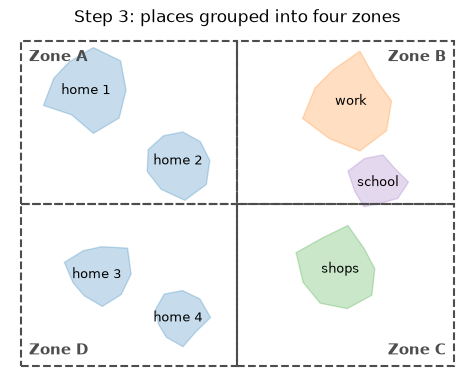

zone
A    home 1, home 2
B      work, school
C             shops
D    home 3, home 4
Name: places in zone, dtype: str

In [5]:
# Group the places into four zones.
def zone_of(x, y):
    """Top row is A (left) and B (right). Bottom row is D (left) and C (right)."""
    if y >= 3:
        return "A" if x < 4 else "B"
    return "D" if x < 4 else "C"

W, H = 4, 3                                               # each zone is 4 km by 3 km
zone_corner = {"A": (0, 3), "B": (4, 3), "C": (4, 0), "D": (0, 0)}    # lower-left corners
label_at = {"A": (0.15, 5.85, "left", "top"), "B": (7.85, 5.85, "right", "top"),
            "C": (7.85, 0.15, "right", "bottom"), "D": (0.15, 0.15, "left", "bottom")}

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.25)
for z, (x, y) in zone_corner.items():
    ax.add_patch(Rectangle((x, y), W, H, fill=False, linestyle="--", edgecolor="0.3", linewidth=1.5))
    lx, ly, ha, va = label_at[z]
    ax.text(lx, ly, f"Zone {z}", fontsize=11, weight="bold", color="0.3", ha=ha, va=va)
ax.set_xlim(-0.2, 8.2)
ax.set_ylim(-0.2, 6.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 3: places grouped into four zones")
plt.show()

pd.DataFrame([{"place": name, "zone": zone_of(cx, cy)} for name, (kind, cx, cy, r) in PLACES.items()]
             ).groupby("zone")["place"].apply(", ".join).rename("places in zone")

### Step 4: zones become points, joined by roads

Two simplifications at once, shown side by side.

**Left:** each zone shrinks to one point, its **node** (or centroid). All its trips start and end there. We lose where in the zone a trip begins; we gain one number per pair of zones.

**Right:** **links** are the roads between nodes. A trip follows a path of links. Two zones with no line between them have no direct road: B and D is the one such pair here, so its trips take a longer route.

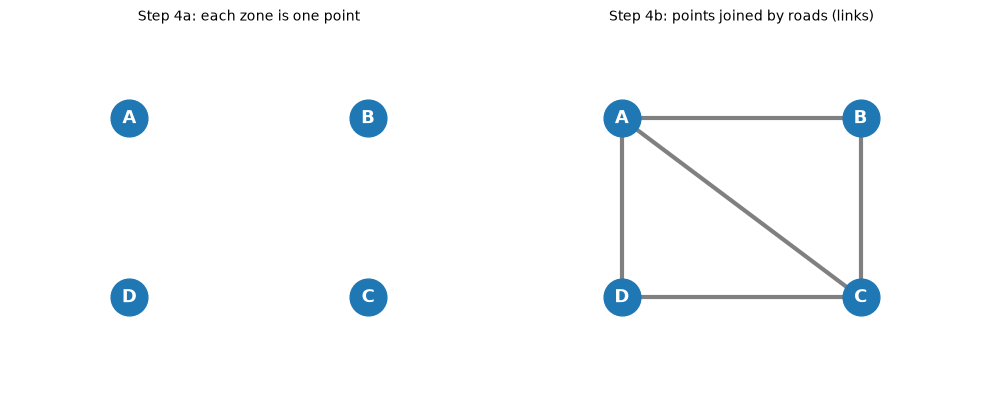

In [6]:
LINK_PAIRS = [("A", "B"), ("B", "C"), ("C", "D"), ("D", "A"), ("A", "C")]

def draw_nodes(ax, size=700, fontsize=13):
    for z, (x, y) in POS.items():
        ax.scatter(x, y, s=size, color="tab:blue", zorder=3)
        ax.text(x, y, z, color="white", ha="center", va="center",
                fontsize=fontsize, weight="bold", zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, with_links, title in [(axes[0], False, "Step 4a: each zone is one point"),
                              (axes[1], True, "Step 4b: points joined by roads (links)")]:
    if with_links:
        for a, b in LINK_PAIRS:
            (x1, y1), (x2, y2) = POS[a], POS[b]
            ax.plot([x1, x2], [y1, y2], color="0.5", linewidth=3, zorder=1)
    draw_nodes(ax)
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

### Step 5: each link gets a time and a capacity

A road needs numbers before the model can use it. Each link gets two:

- **Free-flow time:** how long it takes when the road is empty. Used from Part C onwards.
- **Capacity:** how many vehicles per hour it can carry. Not needed until Part J, where traffic jams are added.

The values are in the links table in Part A.

### Step 6: a zone is an area, not a point

A trip that starts and ends in the same zone still takes time, and a bigger zone means longer trips inside it. The toy model gives such a trip half the time to the nearest zone (Part A).

This is the first point where the **size** of a zone matters, which is why it comes last.

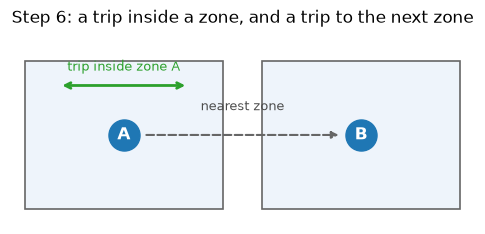

In [7]:
# One zone as an area, with a trip inside it and the trip to the nearest zone.
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.add_patch(Rectangle((0, 0), 4, 3, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2))
ax.add_patch(Rectangle((4.8, 0), 4, 3, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2))
centroid_a, centroid_b = (2, 1.5), (6.8, 1.5)
for (x, y), z in [(centroid_a, "A"), (centroid_b, "B")]:
    ax.scatter(x, y, s=500, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=12, weight="bold", zorder=4)

ax.annotate("", xy=(3.3, 2.5), xytext=(0.7, 2.5),
            arrowprops=dict(arrowstyle="<->", color="tab:green", lw=2))
ax.text(2, 2.8, "trip inside zone A", ha="center", fontsize=9, color="tab:green")
ax.annotate("", xy=(centroid_b[0] - 0.4, 1.5), xytext=(centroid_a[0] + 0.4, 1.5),
            arrowprops=dict(arrowstyle="-|>", color="0.4", lw=1.5, linestyle="--"))
ax.text(4.4, 2.0, "nearest zone", ha="center", fontsize=9, color="0.3")
ax.set_xlim(-0.3, 9.1)
ax.set_ylim(-0.3, 3.6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 6: a trip inside a zone, and a trip to the next zone")
plt.show()

## What we leave out, for now

| Left out | Why | Where it comes back |
|---|---|---|
| Where in a zone a trip starts | One point per zone | Part A, trips inside a zone |
| Roads joining centroids to the network | Toy network | Never here; real models add them |
| One-way roads | Same time both ways | Never here; real networks have them |
| Traffic jams | Free-flow times only | Level 5, Part J |
| Trips other than work | Work only | Level 2, Part F |
| Modes other than car and bus | Car and bus only | Never here |
| Checks against real data | Made-up counts and times | Level 6, Parts L to N |
| Time of day | AM peak only | `docs/methodology.md`, Scope |

# Level 1: work trips, travel time only

One kind of trip (work), one mode, and travel time as the only thing that puts people off. Four parts: build the travel times, set how many trips start and end in each zone, work out how much time puts people off, then balance the trips.

**Why:** it is the smallest model that answers "where do the trips go?", and you can check it by hand.

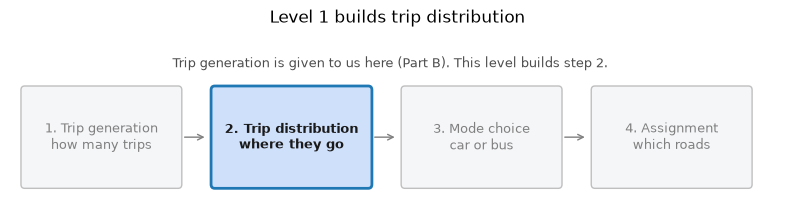

In [8]:
draw_stages(active={2}, note="Trip generation is given to us here (Part B). This level builds step 2.",
            title="Level 1 builds trip distribution")

## Part A. Travel times between zones

**Question.** How long does it take to get from each zone to each other zone?

**What we need:**

1. The **links**: which zones they join, their free-flow time, and their capacity.
2. The **shortest time** between every pair of zones.

**Assumption:** links are two-way and take the same time in both directions.

**TAG:** M3.1 §2.4, network structure — not checked. Times and capacities are placeholders.

In [9]:
# Five two-way links between the four zones. Capacities were raised once both kinds of trip
# were assigned: the work-only capacities gave flows above 2.5 times capacity on some links.
links = pd.DataFrame(
    [
        ("A", "B", 10, 150),
        ("B", "C", 12, 125),
        ("C", "D", 8, 250),
        ("D", "A", 15, 150),
        ("A", "C", 20, 100),
    ],
    columns=["from", "to", "free_flow_min", "capacity_vph"],
)
links

,from,to,free_flow_min,capacity_vph
0,A,B,10,150
1,B,C,12,125
2,C,D,8,250
3,D,A,15,150
4,A,C,20,100


### The shortest time between each pair

With five links you can do this in your head. Take **A to C**:

- straight along the A-C road: **20 min**
- round through B: 10 + 12 = 22 min
- round through D: 15 + 8 = 23 min

So the quickest is 20 minutes, going direct. Doing the same for all six pairs gives the table below.

**B to D has no direct road.** Its quickest route is B - C - D, which takes 12 + 8 = 20 minutes. This is the only pair where the shortest time is not simply a single road, and it is worth noticing: in a real network with thousands of links, almost every pair is like this.

Computers use a standard algorithm rather than doing this by hand. That algorithm is in the Appendix, which also checks the table below is right.

In [10]:
# The shortest times, worked out by hand above (minutes).
shortest_by_hand = {
    ("A", "B"): (10, "A - B"),
    ("A", "C"): (20, "A - C"),
    ("A", "D"): (15, "A - D"),
    ("B", "C"): (12, "B - C"),
    ("B", "D"): (20, "B - C - D"),
    ("C", "D"): (8,  "C - D"),
}

# Direct link times as a matrix: no direct link = infinity, a zone to itself = 0.
link_time = np.full((n, n), np.inf)
np.fill_diagonal(link_time, 0.0)
for _, row in links.iterrows():
    i, j = idx[row["from"]], idx[row["to"]]
    link_time[i, j] = link_time[j, i] = row["free_flow_min"]

# The same times as a matrix, for the rest of the notebook.
best = np.zeros((n, n))
for (a, b), (mins, _) in shortest_by_hand.items():
    best[idx[a], idx[b]] = best[idx[b], idx[a]] = mins
assert np.allclose(best, best.T), "the matrix should be symmetric"

pd.DataFrame(
    [{"pair": f"{a} to {b}",
      "direct road (min)": "no road" if np.isinf(link_time[idx[a], idx[b]]) else link_time[idx[a], idx[b]],
      "shortest (min)": mins,
      "route": route}
     for (a, b), (mins, route) in shortest_by_hand.items()]
)

,pair,direct road (min),shortest (min),route
0,A to B,10.0,10,A - B
1,A to C,20.0,20,A - C
2,A to D,15.0,15,A - D
3,B to C,12.0,12,B - C
4,B to D,no road,20,B - C - D
5,C to D,8.0,8,C - D


### Zone areas and links on the map

Each zone is an **area** (a rectangle). Its **centroid** (the dot) stands for the whole zone. Lines join centroids, and a thicker line carries more traffic.

The zone areas are made up: each is 4 km by 3 km, so 12 km². Area matters because a bigger zone means longer trips inside it (Step 6).

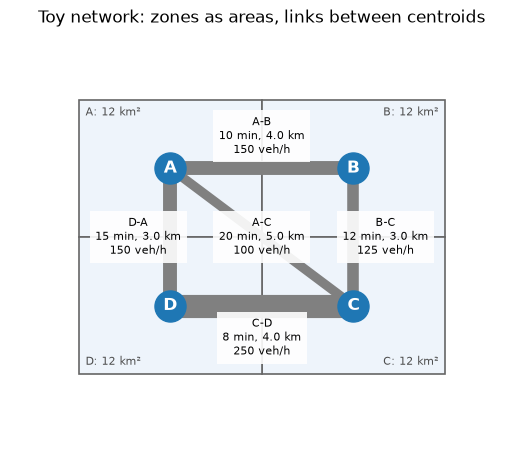

,from,to,free_flow_min,capacity_vph,distance_km
0,A,B,10,150,4.0
1,B,C,12,125,3.0
2,C,D,8,250,4.0
3,D,A,15,150,3.0
4,A,C,20,100,5.0


In [11]:
centre = (4, 3)                                           # middle of the study area

links_map = links.copy()
links_map["distance_km"] = [
    round(float(np.hypot(POS[a][0] - POS[b][0], POS[a][1] - POS[b][1])), 1)
    for a, b in zip(links_map["from"], links_map["to"])
]

def push_from_centre(x1, y1, x2, y2, by=0.7):
    """Midpoint of a link, nudged away from the centre so a label sits beside the line."""
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    dx, dy = mx - centre[0], my - centre[1]
    norm = np.hypot(dx, dy)
    return (mx + by * dx / norm, my + by * dy / norm) if norm > 0 else (mx, my)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for z, (x, y) in zone_corner.items():
    ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2, zorder=0))
for z, (lx, ly, ha, va) in label_at.items():
    ax.text(lx, ly, f"{z}: {W * H} km²", fontsize=8, color="0.3", ha=ha, va=va, zorder=1)

for _, row in links_map.iterrows():
    (x1, y1), (x2, y2) = POS[row["from"]], POS[row["to"]]
    ax.plot([x1, x2], [y1, y2], color="0.5", linewidth=row["capacity_vph"] / 15,
            solid_capstyle="round", zorder=2)
    mx, my = push_from_centre(x1, y1, x2, y2)
    ax.text(mx, my, f"{row['from']}-{row['to']}\n{row['free_flow_min']} min, {row['distance_km']} km\n"
                    f"{row['capacity_vph']} veh/h",
            ha="center", va="center", fontsize=8, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
draw_nodes(ax, size=500, fontsize=12)

ax.set_aspect("equal")
ax.set_xlim(-1.5, 9.5)
ax.set_ylim(-1.5, 7.5)
ax.axis("off")
ax.set_title("Toy network: zones as areas, links between centroids")
plt.show()

links_map

### Trips inside a zone

A trip from a zone to itself still takes time, but less than a trip to the next zone. The rule of thumb is **half the time to the nearest other zone**.

Putting zero here would be wrong: Part C treats cheap trips as attractive, so zero-cost trips inside a zone would soak up the whole model.

**TAG:** M2.2 §5.2.28 and M2.1 §2.4.4, intra-zonal costs — matches TAG. TAG also says to cap this for large zones, which four zones do not need.

In [12]:
# Travel time matrix c (minutes). Time inside a zone = half the time to the nearest other zone.
c = best.copy()
for i in range(n):
    c[i, i] = min(best[i, j] for j in range(n) if j != i) / 2

assert np.allclose(c, c.T), "the matrix should be symmetric"
pd.DataFrame(c, index=ZONES, columns=ZONES)

,A,B,C,D
A,5.0,10.0,20.0,15.0
B,10.0,5.0,12.0,20.0
C,20.0,12.0,4.0,8.0
D,15.0,20.0,8.0,4.0


## Part B. How many trips start and end in each zone

**Question.** How many work trips start and end in each zone?

Every trip has one start and one end, so the two totals must be equal:

$$\sum_i P_i = \sum_j A_j$$

- **Productions** $P_i$: trips starting in zone $i$. For work trips, the workers who live there.
- **Attractions** $A_j$: trips ending in zone $j$. For work trips, the jobs there.

A first guess at the attractions rarely adds up to the productions total, so we scale it:

$$A_j = A_j^{\text{raw}} \cdot \frac{\sum_i P_i}{\sum_k A_k^{\text{raw}}}$$

We keep the productions and scale the attractions, because productions come from household data and are usually more reliable.

**TAG:** not checked. Trip generation sits outside this toy model; these numbers are placeholders.

In [13]:
P_w = np.array([400.0, 300.0, 200.0, 100.0])      # work trips starting in each zone, trips/h
A_raw = np.array([550.0, 150.0, 150.0, 250.0])    # first guess at trips ending in each zone

A_w = A_raw * (P_w.sum() / A_raw.sum())

print("sum of P_w   =", P_w.sum())
print("sum of A_raw =", A_raw.sum())
print("sum of A_w   =", A_w.sum())
print("A_w          =", A_w)
assert np.isclose(P_w.sum(), A_w.sum())

sum of P_w   = 1000.0
sum of A_raw = 1100.0
sum of A_w   = 1000.0
A_w          = [500.     136.3636 136.3636 227.2727]


### Productions and attractions on the map

Orange arrows point out of a zone: trips **starting** there. Green arrows point in: trips **ending** there. The two totals are equal, as the equation requires. The values are placeholders.

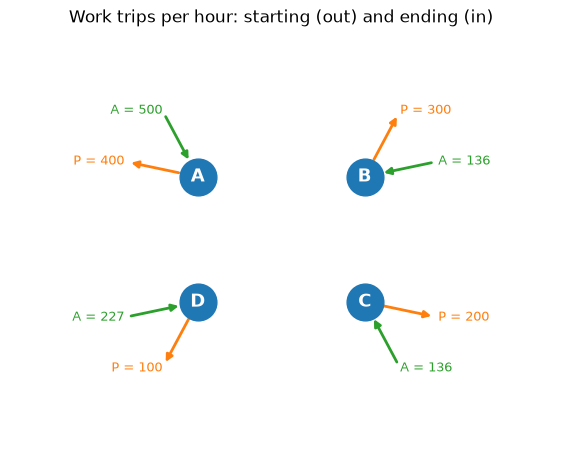

In [14]:
hub = np.array([4.0, 3.0])

def turn(v, deg):
    t = np.radians(deg)
    return np.array([v[0] * np.cos(t) - v[1] * np.sin(t), v[0] * np.sin(t) + v[1] * np.cos(t)])

fig, ax = plt.subplots(figsize=(7, 5.5))
for k, z in enumerate(ZONES):
    p = np.array(POS[z], dtype=float)
    out_dir = (p - hub) / np.linalg.norm(p - hub)
    for direction, colour, value, label in [(turn(out_dir, 25), "tab:orange", P_w[k], "P"),
                                            (turn(out_dir, -25), "tab:green", A_w[k], "A")]:
        if label == "P":
            ax.annotate("", xy=p + 1.7 * direction, xytext=p + 0.4 * direction,
                        arrowprops=dict(arrowstyle="-|>", color=colour, lw=2))
        else:
            ax.annotate("", xy=p + 0.4 * direction, xytext=p + 1.7 * direction,
                        arrowprops=dict(arrowstyle="-|>", color=colour, lw=2))
        ax.text(*(p + 1.8 * direction), f"{label} = {value:.0f}", color=colour,
                ha="left" if direction[0] > 0 else "right", va="center", fontsize=9)
draw_nodes(ax)
ax.set_xlim(-2.5, 10.5)
ax.set_ylim(-2, 8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Work trips per hour: starting (out) and ending (in)")
plt.show()

## Part C. How travel time puts people off

**Question.** A pair of zones is 20 minutes apart. How keen are people to make that trip?

We give each pair of zones a **weight**: a number saying how attractive that trip is, before we worry about totals. A high weight means a popular trip. Two ideas fix its shape:

- People prefer shorter trips, so the weight falls as travel time rises.
- Each extra minute should put off the same *share* of trips, not the same number. Going from 10 to 20 minutes should cut trips by the same percentage as going from 40 to 50.

The function with that property is:

$$f(c) = e^{-\beta c}$$

- $f(0) = 1$: no travel time, nothing putting people off.
- $f$ never goes negative, so trips cannot go below zero.
- $\beta$ (per minute) sets how fast the weight falls. A bigger $\beta$ means people give up on long trips sooner.

We use $\beta = 0.05$ for work trips. A 9-minute trip keeps about 64% of its weight, a 60-minute trip about 5%.

**TAG:** M2.1 §4.9.14, model form — matches TAG. M2.2 §5.2.31 says to calibrate $\beta$ against observed trip lengths, so 0.05 is a placeholder until Phase 3.

In [15]:
beta_w = 0.05   # per minute, work trips (placeholder)

def deterrence(t, beta):
    return np.exp(-beta * t)

F_w = deterrence(c, beta_w)   # F_w[i, j] = f(c_ij)
pd.DataFrame(F_w, index=ZONES, columns=ZONES).round(3)

,A,B,C,D
A,0.779,0.607,0.368,0.472
B,0.607,0.779,0.549,0.368
C,0.368,0.549,0.819,0.670
D,0.472,0.368,0.670,0.819


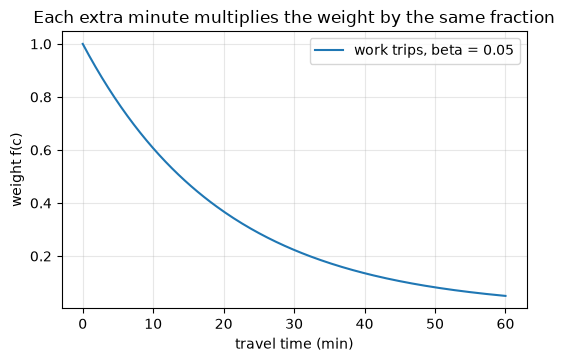

In [16]:
t = np.linspace(0, 60, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(t, deterrence(t, beta_w), label=f"work trips, beta = {beta_w}")
ax.set_xlabel("travel time (min)")
ax.set_ylabel("weight f(c)")
ax.set_title("Each extra minute multiplies the weight by the same fraction")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Part D. A first guess

**Question.** If trips depended only on zone size and travel time, how many would there be?

A zone sends and receives more trips if it is big. A pair of zones trades more trips if it is close. So multiply the three things together:

$$T^0_{ij} = P_i \, A_j \, f(c_{ij})$$

This is Newton's gravity: two bodies pull on each other in proportion to their masses, and the pull falls off with distance.

**The problem.** Nothing makes the row totals come to $P_i$ or the column totals come to $A_j$. The numbers below are far too big, because a production in the hundreds times an attraction in the hundreds gives tens of thousands. Part E fixes this.

In [17]:
T0 = P_w[:, None] * A_w[None, :] * F_w   # T0[i, j] = P_i * A_j * f(c_ij)

print("row totals:    ", T0.sum(axis=1).round(1), "  should be P:", P_w)
print("column totals: ", T0.sum(axis=0).round(1), "  should be A:", A_w.round(1))

row totals:     [251852.2 170373.7 104553.6  56383.1]   should be P: [400. 300. 200. 100.]
column totals:  [307146.   84927.7  73987.3 117101.7]   should be A: [500.  136.4 136.4 227.3]


### What each of the three parts does

Each panel changes one thing and leaves the others alone, so you can see what it does to the trips from A to B.

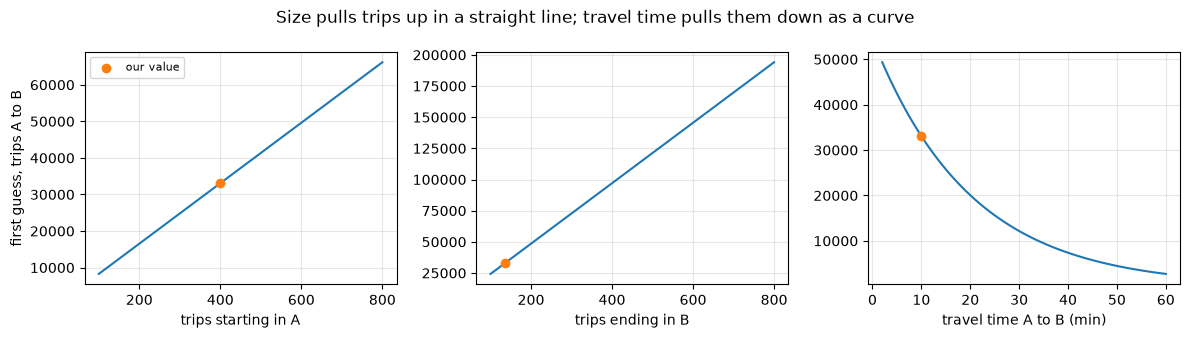

In [18]:
i0, j0 = idx["A"], idx["B"]
P_A, A_B, c_AB = P_w[i0], A_w[j0], c[i0, j0]

# Each panel varies one of the three ingredients and holds the other two at our values.
panels = [
    ("trips starting in A",      np.linspace(100, 800, 100), P_A,
     lambda v: v * A_B * deterrence(c_AB, beta_w)),
    ("trips ending in B",        np.linspace(100, 800, 100), A_B,
     lambda v: P_A * v * deterrence(c_AB, beta_w)),
    ("travel time A to B (min)", np.linspace(2, 60, 100),    c_AB,
     lambda v: P_A * A_B * deterrence(v, beta_w)),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for k, (ax, (xlabel, xs, ours, f)) in enumerate(zip(axes, panels)):
    ax.plot(xs, f(xs), color="tab:blue")
    ax.scatter([ours], [f(ours)], color="tab:orange", zorder=3, label="our value")
    ax.set_xlabel(xlabel)
    ax.grid(alpha=0.3)
    if k == 0:
        ax.set_ylabel("first guess, trips A to B")
        ax.legend(fontsize=8)
fig.suptitle("Size pulls trips up in a straight line; travel time pulls them down as a curve")
plt.tight_layout()
plt.show()

## Part E. Balancing the trips (the Furness method)

**Question.** How do we fix the first guess so every zone sends out exactly $P_i$ trips and takes in exactly $A_j$?

Multiply each row by a number $a_i$, and each column by a number $b_j$:

$$T_{ij} = a_i \, b_j \, P_i \, A_j \, f(c_{ij})$$

We need both to hold:

- rows: $\sum_j T_{ij} = P_i$
- columns: $\sum_i T_{ij} = A_j$

Solve the row rule for $a_i$, holding the $b$s still:

$$a_i = \frac{1}{\sum_j b_j \, A_j \, f(c_{ij})}$$

and the column rule gives the same kind of thing for $b_j$:

$$b_j = \frac{1}{\sum_i a_i \, P_i \, f(c_{ij})}$$

Each rule needs the answer to the other, so we cannot solve both at once. **Furness** takes turns instead: fix the rows, then fix the columns, then fix the rows again, until both are right at once.

**TAG:** M2.1 §4.9.12, doubly constrained for commuting — matches TAG. The 0.1% stopping point is our own choice.

### What taking turns actually does

Watch the margins. Fixing the rows breaks the columns, and fixing the columns breaks the rows, but each time by less. After a few turns both are right.

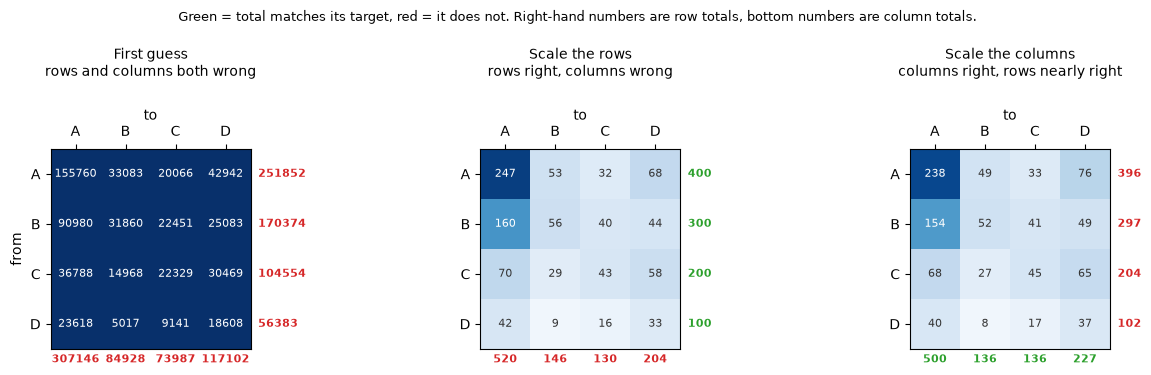

after scaling rows then columns, the largest row error is 2.4% - so we go round again


In [19]:
M0 = T0.copy()
M1 = M0 * (P_w / M0.sum(axis=1))[:, None]      # scale each row so its total is P
M2 = M1 * (A_w / M1.sum(axis=0))[None, :]      # scale each column so its total is A

def margin_panel(ax, M, title, vmax):
    """Show a trip matrix with its row and column totals, green if they match the target."""
    ax.imshow(M, cmap="Blues", vmin=0, vmax=vmax * 1.1)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] > 0.6 * vmax else "0.2")
    rows, cols = M.sum(axis=1), M.sum(axis=0)
    for i in range(n):
        ok = np.isclose(rows[i], P_w[i], rtol=5e-3)
        ax.text(n - 0.35, i, f"{rows[i]:.0f}", ha="left", va="center", fontsize=8,
                color="tab:green" if ok else "tab:red", weight="bold")
    for j in range(n):
        ok = np.isclose(cols[j], A_w[j], rtol=5e-3)
        ax.text(j, n - 0.4, f"{cols[j]:.0f}", ha="center", va="top", fontsize=8,
                color="tab:green" if ok else "tab:red", weight="bold")
    ax.set_xticks(range(n), ZONES)
    ax.set_yticks(range(n), ZONES)
    ax.xaxis.tick_top()                     # zone labels on top, so the totals below stay clear
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("to")
    ax.set_title(title, fontsize=10, pad=24)

top = M2.max()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
margin_panel(axes[0], M0, "First guess\nrows and columns both wrong", top)
margin_panel(axes[1], M1, "Scale the rows\nrows right, columns wrong", top)
margin_panel(axes[2], M2, "Scale the columns\ncolumns right, rows nearly right", top)
axes[0].set_ylabel("from")
fig.suptitle("Green = total matches its target, red = it does not. Right-hand numbers are row totals, "
             "bottom numbers are column totals.", fontsize=9)
plt.tight_layout()
plt.show()

print("after scaling rows then columns, the largest row error is",
      f"{np.max(np.abs(M2.sum(axis=1) / P_w - 1)):.1%}", "- so we go round again")

### The loop in code

Each pass does what the picture above did, and stops when the totals stop moving by more than 0.1%.

**Guard.** A zero production or attraction would divide by zero, so the function refuses those inputs.

In [20]:
def furness(P, A, F, tol=1e-3, max_iter=100):
    """Doubly constrained gravity model. Returns the trip matrix, the a and b factors, and a history."""
    assert np.all(P > 0) and np.all(A > 0), "zero productions or attractions cause division by zero"
    a = np.ones(len(P))
    b = np.ones(len(A))
    prev_row = prev_col = None
    history = []                      # (iteration, change, error), for the convergence chart
    for it in range(1, max_iter + 1):
        a = 1.0 / (F @ (b * A))          # row rule
        b = 1.0 / (F.T @ (a * P))        # column rule
        T = a[:, None] * b[None, :] * P[:, None] * A[None, :] * F
        row, col = T.sum(axis=1), T.sum(axis=0)
        error = max(np.max(np.abs(row / P - 1)), np.max(np.abs(col / A - 1)))
        if prev_row is None:
            change = np.nan
        else:
            change = max(np.max(np.abs(row / prev_row - 1)), np.max(np.abs(col / prev_col - 1)))
        print(f"pass {it:2d}: largest change in totals {change:.6f}   error against targets {error:.6f}")
        history.append((it, change, error))
        if prev_row is not None and change < tol:
            break
        prev_row, prev_col = row, col
    return T, a, b, history

In [21]:
T_w, a_w, b_w, furness_hist = furness(P_w, A_w, F_w, tol=1e-3)
print()
print("a_w =", a_w)
print("b_w =", b_w)

pass  1: largest change in totals nan   error against targets 0.023819
pass  2: largest change in totals 0.022187   error against targets 0.001240
pass  3: largest change in totals 0.001167   error against targets 0.000072
pass  4: largest change in totals 0.000067   error against targets 0.000004

a_w = [0.0016 0.0018 0.0019 0.0017]
b_w = [0.959  0.9313 1.0512 1.1212]


### Checking one number by hand

The notebook claims you can check it by hand, so here is one number checked by hand: the work trips from **A to B**. Multiply the five pieces together and compare with what the code produced.

In [22]:
i0, j0 = idx["A"], idx["B"]
pieces = [
    ("a_A  (row factor for A)", a_w[i0]),
    ("b_B  (column factor for B)", b_w[j0]),
    ("P_A  (trips starting in A)", P_w[i0]),
    ("A_B  (trips ending in B)", A_w[j0]),
    (f"f(c) (weight for {c[i0, j0]:.0f} min)", F_w[i0, j0]),
]
running = 1.0
for name, value in pieces:
    running *= value
    print(f"{name:<34} = {value:12.6f}    running product = {running:12.4f}")

print()
print(f"by hand:   {running:.4f} trips/h from A to B")
print(f"from code: {T_w[i0, j0]:.4f} trips/h")
assert np.isclose(running, T_w[i0, j0]), "the hand check must match the code"
print("they agree.")

a_A  (row factor for A)            =     0.001604    running product =       0.0016
b_B  (column factor for B)         =     0.931289    running product =       0.0015
P_A  (trips starting in A)         =   400.000000    running product =       0.5974
A_B  (trips ending in B)           =   136.363636    running product =      81.4616
f(c) (weight for 10 min)           =     0.606531    running product =      49.4089

by hand:   49.4089 trips/h from A to B
from code: 49.4089 trips/h
they agree.


### Furness settling down

Both lines fall each pass: how much the totals moved, and how far they are from the targets. We stop below the red line (0.1%).

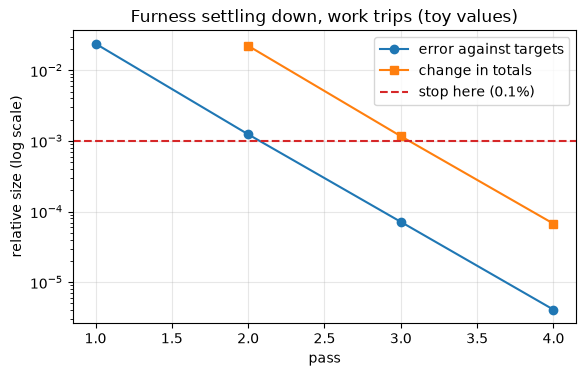

In [23]:
its = [h[0] for h in furness_hist]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(its, [h[2] for h in furness_hist], marker="o", label="error against targets")
ax.semilogy(its[1:], [h[1] for h in furness_hist[1:]], marker="s", label="change in totals")
ax.axhline(1e-3, color="tab:red", linestyle="--", label="stop here (0.1%)")
ax.set_xlabel("pass")
ax.set_ylabel("relative size (log scale)")
ax.set_title("Furness settling down, work trips (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### The finished trip matrix

Each cell is the trips per hour from one zone (row) to another (column). The diagonal is trips that start and end in the same zone. Darker means more trips.

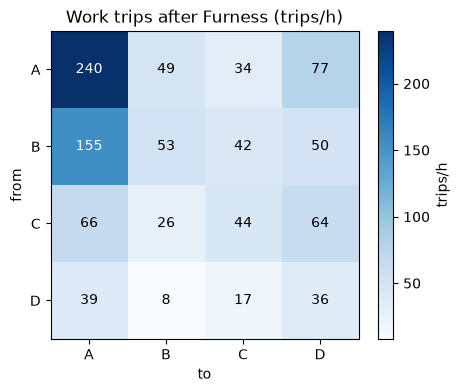

row totals:     [400. 300. 200. 100.]   should be P: [400. 300. 200. 100.]
column totals:  [500.   136.36 136.36 227.27]   should be A: [500.   136.36 136.36 227.27]


,A,B,C,D
A,239.6,49.4,33.8,77.2
B,155.2,52.8,42.0,50.0
C,66.0,26.1,43.9,63.9
D,39.2,8.1,16.6,36.1


In [24]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(T_w, cmap="Blues")
ax.set_xticks(range(n), ZONES)
ax.set_yticks(range(n), ZONES)
ax.set_xlabel("to")
ax.set_ylabel("from")
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{T_w[i, j]:.0f}", ha="center", va="center",
                color="white" if T_w[i, j] > 0.6 * T_w.max() else "black")
ax.set_title("Work trips after Furness (trips/h)")
fig.colorbar(im, ax=ax, label="trips/h")
plt.show()

print("row totals:    ", T_w.sum(axis=1).round(2), "  should be P:", P_w)
print("column totals: ", T_w.sum(axis=0).round(2), "  should be A:", A_w.round(2))
pd.DataFrame(T_w, index=ZONES, columns=ZONES).round(1)

### Are the trips the right length?

Matching the totals is not enough: the trips should also be the right *length*. We group them into time bands and work out the **mean trip length**, the average time per trip:

$$\bar{c} = \frac{\sum_{i,j} T_{ij} \, c_{ij}}{\sum_{i,j} T_{ij}}$$

If the bands or the mean look wrong, $\beta$ is wrong. This is how $\beta$ gets tuned once there is real data.

**TAG:** M2.2 §5.2.31, calibrate against observed trip lengths — placeholder. There is no observed data here, so this is not yet a real test.

In [25]:
BANDS = [0, 10, 20, 30, np.inf]
BAND_LABELS = ["0-10 min", "10-20 min", "20-30 min", "30+ min"]

def trip_length_summary(T, c):
    """Share of trips in each time band, and the mean trip length (min)."""
    shares = [T[(c >= lo) & (c < hi)].sum() / T.sum() for lo, hi in zip(BANDS[:-1], BANDS[1:])]
    return pd.Series(shares, index=BAND_LABELS, name="share of trips").round(3), round((T * c).sum() / T.sum(), 2)

shares_w, mean_w = trip_length_summary(T_w, c)
print("work trips, mean trip length (min):", mean_w)
shares_w

work trips, mean trip length (min): 10.19


0-10 min     0.453
10-20 min    0.389
20-30 min    0.158
30+ min      0.000
Name: share of trips, dtype: float64

# Level 2: a second kind of trip

Now we add shopping, leisure and personal business, which modellers call **home-based other** trips. Two things change:

- Shoppers choose where to go. So the attraction numbers are only **relative weights**, not fixed totals.
- Shoppers will not travel as far as commuters, so their $\beta$ is bigger.

**Why:** work is only part of the travel. Other trips go to different places, so a work-only model would put the trips in the wrong places.

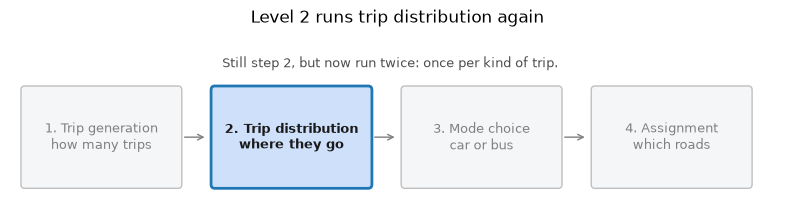

In [26]:
draw_stages(active={2}, note="Still step 2, but now run twice: once per kind of trip.",
            title="Level 2 runs trip distribution again")

## Part F. Trips where only the start is fixed

**The change.** Drop the column rule. Keep the row rule, and let each destination's weight $W_j$ decide its share:

$$T_{ij} = a_i \, P_i \, W_j \, f(c_{ij}), \qquad a_i = \frac{1}{\sum_j W_j \, f(c_{ij})}$$

The row rule gives $a_i$ straight away, so **there is no loop this time**. The column totals land wherever they land, and we look at them afterwards rather than forcing them.

**Why it differs from work trips.** Work trips have a fixed start *and* a fixed end: the houses and the jobs are both known. Shopping trips have a fixed start only, because the shopper picks the shop. Modellers call the first kind **doubly constrained** and the second **singly constrained**.

**TAG:** M2.1 §4.9.12, singly constrained for shopping and leisure — matches TAG.

In [27]:
def singly_constrained(P, W, F):
    """Each row totals P_i. W_j are relative attraction weights, not trip totals."""
    assert np.all(P > 0) and np.all(W > 0), "zero productions or weights cause division by zero"
    a = 1.0 / (F @ W)                       # one pass: no loop
    return a[:, None] * P[:, None] * W[None, :] * F, a

P_o = np.array([300.0, 250.0, 200.0, 150.0])   # other trips starting in each zone, trips/h
W_o = np.array([2.0, 1.0, 1.5, 1.0])           # how attractive each zone is (relative, not trips)
beta_o = 0.10                                  # per minute: shoppers give up sooner (placeholder)

F_o = deterrence(c, beta_o)
T_o, a_o = singly_constrained(P_o, W_o, F_o)

print("row totals:", T_o.sum(axis=1).round(2), "  should be P_o:", P_o)
print("column totals (not forced):", T_o.sum(axis=0).round(1))

row totals: [300. 250. 200. 150.]   should be P_o: [300. 250. 200. 150.]
column totals (not forced): [338.1 173.8 240.6 147.4]


In [28]:
shares_o, mean_o = trip_length_summary(T_o, c)
print("mean trip length (min) - other:", mean_o, "  work:", mean_w)
pd.DataFrame({"work share": shares_w, "other share": shares_o})

mean trip length (min) - other: 8.85   work: 10.19


,work share,other share
0-10 min,0.453,0.565
10-20 min,0.389,0.341
20-30 min,0.158,0.095
30+ min,0.000,0.000


### Both kinds of trip side by side

Left: shoppers' weight falls faster with time (bigger $\beta$). Right: so their trips come out shorter.

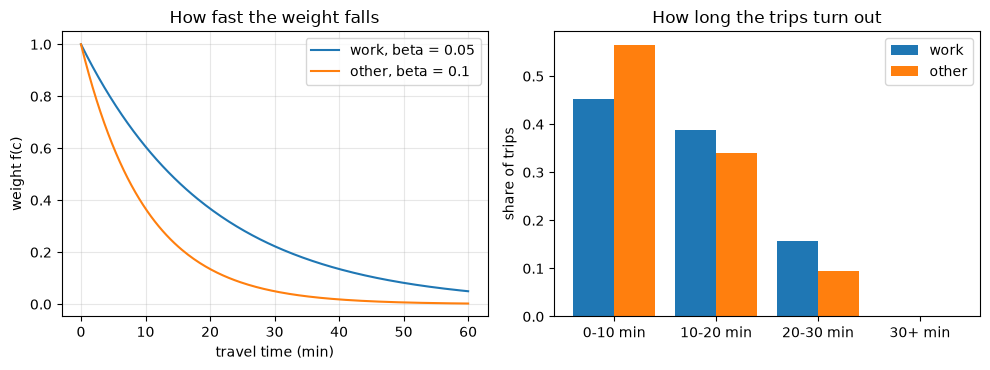

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
t = np.linspace(0, 60, 200)
ax1.plot(t, deterrence(t, beta_w), label=f"work, beta = {beta_w}")
ax1.plot(t, deterrence(t, beta_o), label=f"other, beta = {beta_o}")
ax1.set_xlabel("travel time (min)")
ax1.set_ylabel("weight f(c)")
ax1.set_title("How fast the weight falls")
ax1.grid(alpha=0.3)
ax1.legend()

x = np.arange(len(BAND_LABELS))
ax2.bar(x - 0.2, shares_w.values, width=0.4, label="work")
ax2.bar(x + 0.2, shares_o.values, width=0.4, label="other")
ax2.set_xticks(x, BAND_LABELS)
ax2.set_ylabel("share of trips")
ax2.set_title("How long the trips turn out")
ax2.legend()
plt.tight_layout()
plt.show()

In [30]:
# Both kinds of trip added together. Mode choice and assignment work on this total.
T_all = T_w + T_o
print("total trips/h, work + other:", T_all.sum().round(1))
pd.DataFrame(T_all, index=ZONES, columns=ZONES).round(1)

total trips/h, work + other: 1900.0


,A,B,C,D
A,420.9,104.4,64.2,110.6
B,250.5,131.4,100.5,67.6
C,92.7,55.8,143.2,108.3
D,74.0,18.6,69.1,88.3


### Where the trips go

Each line joins two zones, and its width is the trips both ways added together. Trips inside a zone are not drawn.

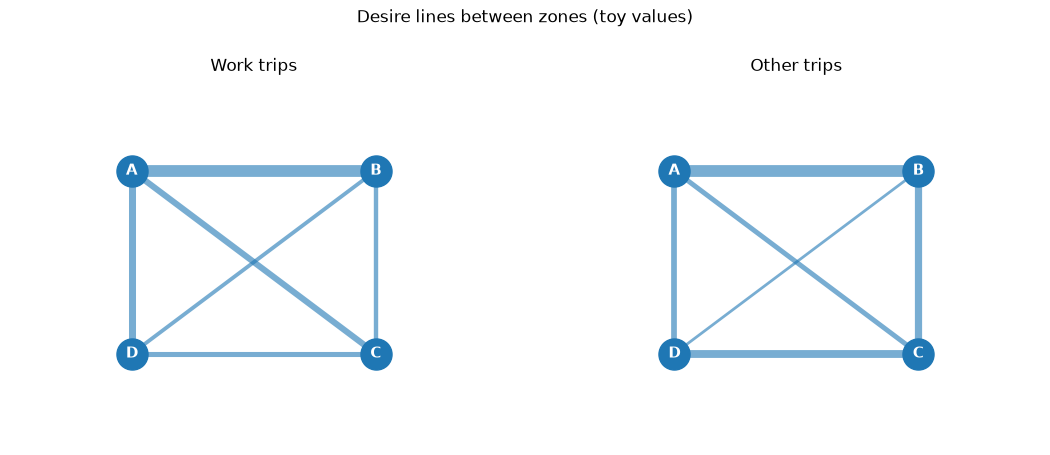

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, T, title in [(axes[0], T_w, "Work trips"), (axes[1], T_o, "Other trips")]:
    two_way = T + T.T
    scale = two_way[np.triu_indices(n, 1)].max()
    for p in range(n):
        for q in range(p + 1, n):
            (x1, y1), (x2, y2) = POS[ZONES[p]], POS[ZONES[q]]
            ax.plot([x1, x2], [y1, y2], color="tab:blue", alpha=0.6,
                    linewidth=0.5 + 8 * two_way[p, q] / scale)
    draw_nodes(ax, size=500, fontsize=11)
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
fig.suptitle("Desire lines between zones (toy values)")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# Level 3: putting every cost in minutes

Before anyone can choose between car and bus, we need one number per option that covers everything: time, fares, and the walking and waiting that go with a bus.

This level adds **one idea only**: turn money and effort into minutes, so the two options can be compared.

**Why:** people do not only care about time. A bus that is quicker but costs more may still lose.

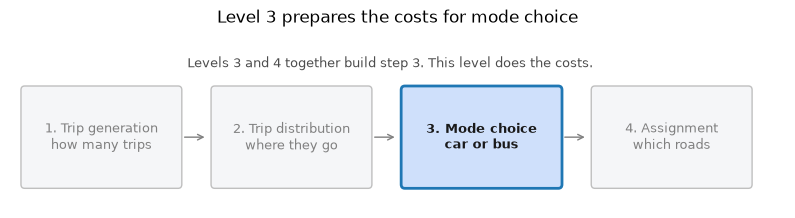

In [32]:
draw_stages(active={3}, note="Levels 3 and 4 together build step 3. This level does the costs.",
            title="Level 3 prepares the costs for mode choice")

## Part G. Generalised cost

**Question.** How do you compare 20 minutes in a car costing £1.50 with 25 minutes on a bus costing £1.80 plus a walk and a wait?

Turn everything into minutes and add it up. That total is the **generalised cost**:

$$GC = \text{time in the vehicle} + w_{\text{walk}} \cdot \text{walk time} + w_{\text{wait}} \cdot \text{wait time} + \frac{\text{money}}{\text{value of time}}$$

Three things to notice:

- **Value of time** turns money into minutes. At £12 an hour, £1.80 is 9 minutes.
- **Walking and waiting count for more** than sitting in a vehicle, because people dislike them more. A minute of walking counts as 2 minutes here.
- The bus is slower in the vehicle too, because it stops: 1.1 times the car time.

**The two options:**

| | car | bus |
|---|---|---|
| time in vehicle | the travel time $c_{ij}$ | 1.1 × $c_{ij}$ |
| walk | none | 3 min, counted double |
| wait | none | 4 min, counted once |
| money | £1.50 parking and fuel | £1.80 fare |

**TAG:** M3.2 §2.7.5 and §3.3.3, cost formula and fares — matches TAG. M3.2 Table 1 weights: walk 2.0 (range 1.5-2.0), wait 1.0, bus in-vehicle 1.1 (range 0.7-1.1) — all within range. M3.1 §2.8.7: value of time comes from TAG unit A1-3, so £12/h is a placeholder.

In [33]:
vot = 0.20                # £ per minute (= £12 per hour, placeholder)
car_money = 1.50          # £ per car trip (placeholder)
bus_fare = 1.80           # £ per bus trip (placeholder)
walk_min, wait_min = 3.0, 4.0
walk_weight = 2.0         # TAG range 1.5 to 2.0
wait_weight = 1.0         # TAG bus waiting weight is 1
bus_ivt_factor = 1.1      # top of TAG range 0.7 to 1.1 (buses stop more)

GC_car = c + car_money / vot
GC_bus = bus_ivt_factor * c + walk_weight * walk_min + wait_weight * wait_min + bus_fare / vot
# GC_bus does not yet include the extra bus penalty, which Part I works out.

print("car money in minutes:", round(car_money / vot, 2))
print("bus fare in minutes: ", round(bus_fare / vot, 2))
display(pd.DataFrame(GC_car, index=ZONES, columns=ZONES).round(1))
display(pd.DataFrame(GC_bus, index=ZONES, columns=ZONES).round(1))

car money in minutes: 7.5
bus fare in minutes:  9.0


,A,B,C,D
A,12.5,17.5,27.5,22.5
B,17.5,12.5,19.5,27.5
C,27.5,19.5,11.5,15.5
D,22.5,27.5,15.5,11.5


,A,B,C,D
A,24.5,30.0,41.0,35.5
B,30.0,24.5,32.2,41.0
C,41.0,32.2,23.4,27.8
D,35.5,41.0,27.8,23.4


### What each cost is made of

The bars break the cost of one trip, A to B, into its parts. Walking and waiting are weighted, so they take up more of the bus bar than their raw minutes would suggest.

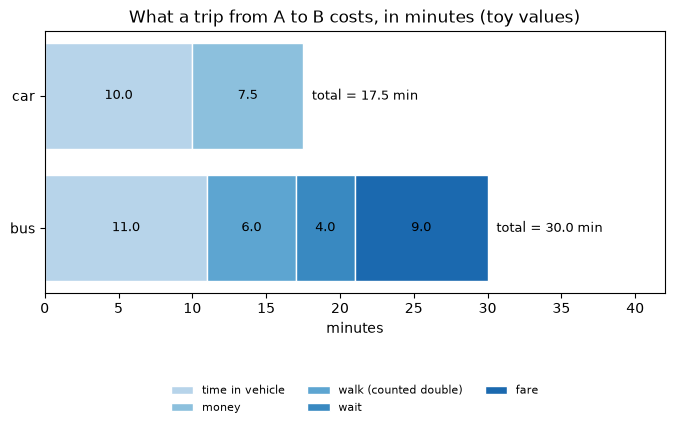

In [34]:
parts_car = [("time in vehicle", c[i0, j0]), ("money", car_money / vot)]
parts_bus = [("time in vehicle", bus_ivt_factor * c[i0, j0]),
             ("walk (counted double)", walk_weight * walk_min),
             ("wait", wait_weight * wait_min),
             ("fare", bus_fare / vot)]

names = ["time in vehicle", "money", "walk (counted double)", "wait", "fare"]
colours = {name: plt.cm.Blues(0.3 + 0.12 * k) for k, name in enumerate(names)}

fig, ax = plt.subplots(figsize=(8, 3.4))
shown = set()
for row_y, parts in [(1, parts_car), (0, parts_bus)]:
    left = 0.0
    for name, val in parts:
        ax.barh(row_y, val, left=left, color=colours[name], edgecolor="white",
                label=None if name in shown else name)
        shown.add(name)
        if val > 1.5:
            ax.text(left + val / 2, row_y, f"{val:.1f}", ha="center", va="center", fontsize=9)
        left += val
    ax.text(left + 0.6, row_y, f"total = {left:.1f} min", va="center", fontsize=9)
ax.set_yticks([1, 0], ["car", "bus"])
ax.set_xlabel("minutes")
ax.set_xlim(0, 42)
ax.set_title("What a trip from A to B costs, in minutes (toy values)")
ax.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.5), ncol=3, frameon=False)
plt.show()

# Level 4: choosing car or bus

Now the trips split between the two options. Two ideas:

1. **Not everyone has the choice.** A household with no car cannot drive, so those trips go by bus whatever the costs say.
2. **Everyone else weighs the costs.** The cheaper option gets more trips, but not all of them: people differ, and the model handles that with a **logit** formula.

**Why:** without a split, every trip would load the roads and the buses would make no difference.

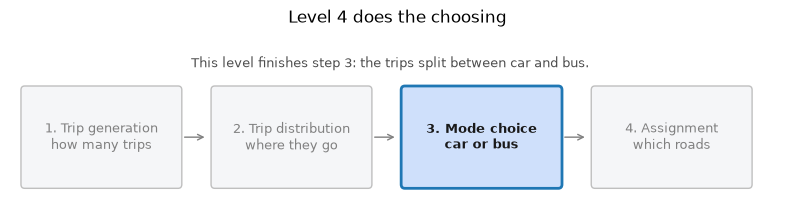

In [35]:
draw_stages(active={3}, note="This level finishes step 3: the trips split between car and bus.",
            title="Level 4 does the choosing")

## Part H. Who has a car

A household with no car cannot choose car, so we set those trips aside before any choosing happens. They all go by bus.

Both shares below are placeholders. The plan (Phase 2) takes them from Census table TS045, and treats car availability as the main thing driving mode choice.

**TAG:** not checked. The plan cites Census TS045 for the zero-car share; 30% is a placeholder.

In [36]:
zero_car_share_w = 0.30   # placeholder: share of work trips from households with no car
zero_car_share_o = 0.30   # placeholder: same value for other trips until sourced

T_own = (1 - zero_car_share_w) * T_w + (1 - zero_car_share_o) * T_o   # car available: a real choice
T_zero = zero_car_share_w * T_w + zero_car_share_o * T_o              # no car: bus only

print("trips/h with a car available:", T_own.sum().round(1))
print("trips/h with no car:         ", T_zero.sum().round(1))
print("check: the two add back to the total?", np.allclose(T_own + T_zero, T_all))

trips/h with a car available: 1330.0
trips/h with no car:          570.0
check: the two add back to the total? True


## Part I. The logit split, and fitting the bus penalty

**Question.** Car costs 27.5 minutes and bus costs 33 minutes. Does *everyone* drive?

No. People value things differently, and the model does not know everything about them. So the cheaper option gets the **larger share**, not all of it. The logit formula does this: give each option a score $e^{-\lambda GC}$, then divide each score by the total.

$$P^{car}_{ij} = \frac{e^{-\lambda \, GC^{car}_{ij}}}{e^{-\lambda \, GC^{car}_{ij}} + e^{-\lambda \, (GC^{bus}_{ij} + k_{bus})}}$$

$\lambda$ sets how sharply people react to a cost gap. A big $\lambda$ means almost everyone takes the cheaper option; a small one means they barely notice.

**The extra bus penalty** $k_{bus}$ covers everything the costs miss: comfort, habit, reliability. (Modellers call it an alternative-specific constant.) We do not guess it. We **fit** it: try values until the model's car share matches a car share we have measured. Since the car share rises as $k_{bus}$ rises, we can close in on the answer by halving an interval again and again.

Here the target is a made-up 70% car share.

**TAG:** M2.1 §4.2, logit form — simplified (ours is one split, TAG describes a hierarchy). M2.1 §4.5.10 says $\lambda$ should be calibrated from data, so 0.1 is a placeholder. M2.1 Table 3 gives destination-choice values, which do not apply here.

In [37]:
lam = 0.1                  # how sharply people react to a cost gap, per minute (placeholder)

def p_car(bus_penalty):
    """Share choosing car, for trips where a car is available."""
    score_car = np.exp(-lam * GC_car)
    score_bus = np.exp(-lam * (GC_bus + bus_penalty))
    return score_car / (score_car + score_bus)

def car_share(bus_penalty):
    """Overall car share across all trips with a car available, weighted by trips."""
    return (p_car(bus_penalty) * T_own).sum() / T_own.sum()

target_car_share = 0.70     # placeholder: the car share we are aiming at

# Halve the interval until it closes on the penalty that hits the target.
lo, hi = -50.0, 50.0
for _ in range(60):
    mid = 0.5 * (lo + hi)
    if car_share(mid) > target_car_share:
        hi = mid            # car share too high, so the bus penalty must come down
    else:
        lo = mid
bus_penalty = 0.5 * (lo + hi)

print(f"fitted bus penalty: {bus_penalty:.2f} minutes")
print(f"car share now:      {car_share(bus_penalty):.4f}   (target {target_car_share})")

fitted bus penalty: -3.98 minutes
car share now:      0.7000   (target 0.7)


### How sharply the cost gap matters

The curve gives the car share for a given cost gap. A bigger $\lambda$ makes the choice swing harder on small differences. Our value is the solid line.

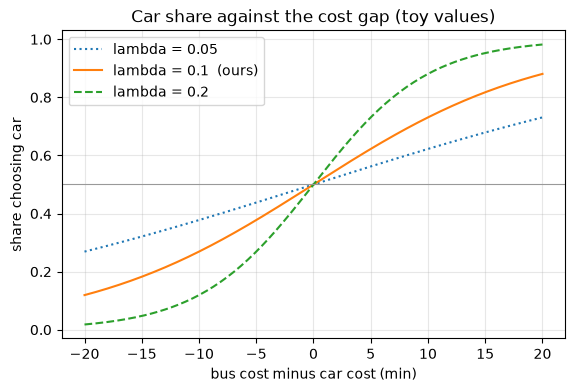

In [38]:
gap = np.linspace(-20, 20, 200)            # bus cost minus car cost, in minutes
fig, ax = plt.subplots(figsize=(6.5, 4))
for lam_try, style in [(0.05, ":"), (lam, "-"), (0.2, "--")]:
    ax.plot(gap, 1 / (1 + np.exp(-lam_try * gap)), style,
            label=f"lambda = {lam_try}" + ("  (ours)" if lam_try == lam else ""))
ax.axhline(0.5, color="0.6", linewidth=0.8)
ax.set_xlabel("bus cost minus car cost (min)")
ax.set_ylabel("share choosing car")
ax.set_title("Car share against the cost gap (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Splitting the trips

Households with no car go by bus. The rest split by the logit. Work and other trips share the same costs, the same $\lambda$ and the same bus penalty, which is a simplification (see Notes).

$$T^{car}_{ij} = P^{car}_{ij} \, T^{own}_{ij} \qquad\qquad T^{bus}_{ij} = (1 - P^{car}_{ij}) \, T^{own}_{ij} + T^{zero}_{ij}$$

**TAG:** not checked. Splitting by car availability is our segmentation choice; TAG's advice on this is in M2.1, still to be located.

In [39]:
P_car_own = p_car(bus_penalty)
T_car_person = P_car_own * T_own                     # people travelling by car
T_bus = (1 - P_car_own) * T_own + T_zero             # people travelling by bus

print("check: car + bus = all trips?", np.allclose(T_car_person + T_bus, T_all))
print("car trips/h:", T_car_person.sum().round(1), "  bus trips/h:", T_bus.sum().round(1))
pd.DataFrame(T_car_person, index=ZONES, columns=ZONES).round(1)

check: car + bus = all trips? True
car trips/h: 931.0   bus trips/h: 969.0


,A,B,C,D
A,203.4,51.2,32.4,55.1
B,123.0,63.5,49.6,34.1
C,46.8,27.6,69.0,52.8
D,36.8,9.4,33.7,42.5


### From trips to modes

Every trip splits by whether a car is available, and then the car-available ones split by cost. Arrow width is trips per hour.

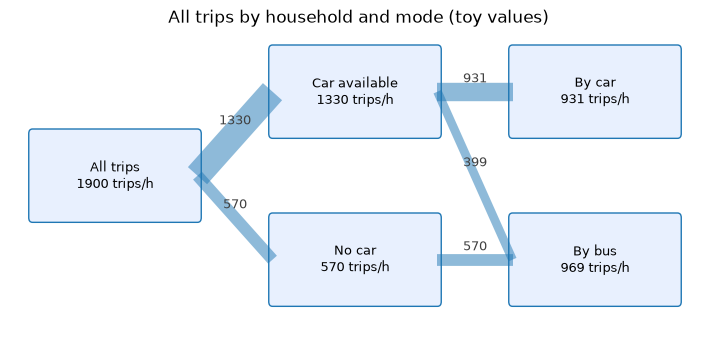

In [40]:
total_all = T_all.sum()
boxes = {
    "All trips": (0.0, 1.3, total_all),
    "Car available": (3.2, 2.2, T_own.sum()),
    "No car": (3.2, 0.4, T_zero.sum()),
    "By car": (6.4, 2.2, T_car_person.sum()),
    "By bus": (6.4, 0.4, T_bus.sum()),
}
edges = [
    ("All trips", "Car available", T_own.sum()),
    ("All trips", "No car", T_zero.sum()),
    ("Car available", "By car", T_car_person.sum()),
    ("Car available", "By bus", T_own.sum() - T_car_person.sum()),
    ("No car", "By bus", T_zero.sum()),
]
fig, ax = plt.subplots(figsize=(9, 4))
for a_name, b_name, value in edges:
    xa, ya, _ = boxes[a_name]
    xb, yb, _ = boxes[b_name]
    ax.plot([xa + 2.2, xb], [ya + 0.45, yb + 0.45], color="tab:blue", alpha=0.5,
            linewidth=1 + 25 * value / total_all, solid_capstyle="butt")
    ax.text((xa + 2.2 + xb) / 2, (ya + yb) / 2 + 0.55, f"{value:.0f}", ha="center",
            fontsize=9, color="0.25")
for name, (x, y, total) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), 2.2, 0.9, boxstyle="round,pad=0.05",
                                facecolor="#e8f0fe", edgecolor="tab:blue"))
    ax.text(x + 1.1, y + 0.45, f"{name}\n{total:.0f} trips/h", ha="center", va="center", fontsize=9)
ax.set_xlim(-0.3, 9)
ax.set_ylim(0, 3.3)
ax.axis("off")
ax.set_title("All trips by household and mode (toy values)")
plt.show()

# Level 5: putting cars on the roads

Car trips now go onto actual roads. Two ideas:

1. **People into vehicles.** A car carries more than one person, so the roads need vehicles, not people.
2. **Traffic jams.** Each driver takes the quickest route, but the more cars on a road, the slower it gets. So the quickest route depends on what everyone else does.

**Why:** congestion is the whole point of a highway model. Until now every road has been empty.

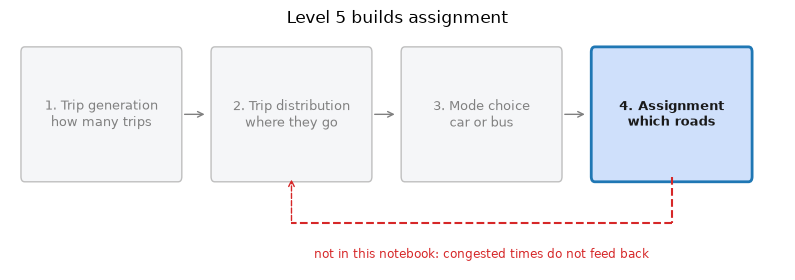

In [41]:
draw_stages(active={4}, feedback=True, title="Level 5 builds assignment")

## Part J. Vehicles, routes and congestion

**From people to vehicles.** Divide by how many people share a car:

$$V_{ij} = \frac{T^{car}_{ij}}{\text{occupancy}}$$

We use 1.1 people per car (placeholder).

**Then three steps for the roads:**

1. **List the routes.** For each pair of zones, find every route that does not double back on itself.
2. **Put everyone on the quickest route**, ignoring jams. Modellers call this all-or-nothing. It is a starting point, not an answer.
3. **Slow the roads down as they fill.** A road's time rises with how full it is:

$$t_a = t^0_a \left(1 + \alpha \left(\frac{v_a}{\text{cap}_a}\right)^{n}\right), \qquad \alpha = 0.15, \quad n = 4$$

The power of 4 keeps the slowdown small while a road is half empty, then makes it climb steeply near capacity. (The literature writes this power as $\beta$; this notebook calls it $n$, because $\beta$ already means the deterrence parameter from Part C.)

**TAG:** M2.2 §5.4.4, car occupancy — placeholder (the data book gives 1.11 for work trips). M3.1 §2.9, speed/flow curves — **not in TAG**: this formula is the US Bureau of Public Roads one, not the curve TAG specifies in Appendix E. Either switch to Appendix E or justify this one.

In [42]:
occupancy = 1.1   # people per car (placeholder)

V_car = T_car_person / occupancy   # vehicles per hour
np.fill_diagonal(V_car, 0.0)       # trips inside a zone do not use the road network

print("car vehicles/h on the network:", V_car.sum().round(1))

car vehicles/h on the network: 502.3


### Step 1: list the routes

For each pair of zones, list every route that never visits a zone twice. From A to C there are three.

In [43]:
# For each zone, the zones it links to and the index of the link.
adj = {z: [] for z in ZONES}
for k, row in links.iterrows():
    adj[row["from"]].append((row["to"], k))
    adj[row["to"]].append((row["from"], k))

def simple_paths(o, d, path=None, used=None):
    """Every route from zone o to zone d that never visits a zone twice.
    Returns a list of (zones, link indices)."""
    path = [o] if path is None else path
    used = [] if used is None else used
    if path[-1] == d:
        return [(path, used)]
    found = []
    for nxt, k in adj[path[-1]]:
        if nxt not in path:
            found += simple_paths(o, d, path + [nxt], used + [k])
    return found

paths = {(o, d): simple_paths(o, d) for o in ZONES for d in ZONES if o != d}

def free_flow_total(p):
    """How long a route takes with empty roads."""
    return sum(links.loc[k, "free_flow_min"] for k in p[1])

routes_ac = sorted(paths[("A", "C")], key=free_flow_total)   # quickest first
for zones, used in routes_ac:
    print(f"{' -> '.join(zones):<16} {free_flow_total((zones, used)):>3} min at free flow")

A -> C            20 min at free flow
A -> B -> C       22 min at free flow
A -> D -> C       23 min at free flow


Drawn out, the three routes look like this. Only the first is a single road; the other two go the long way round.

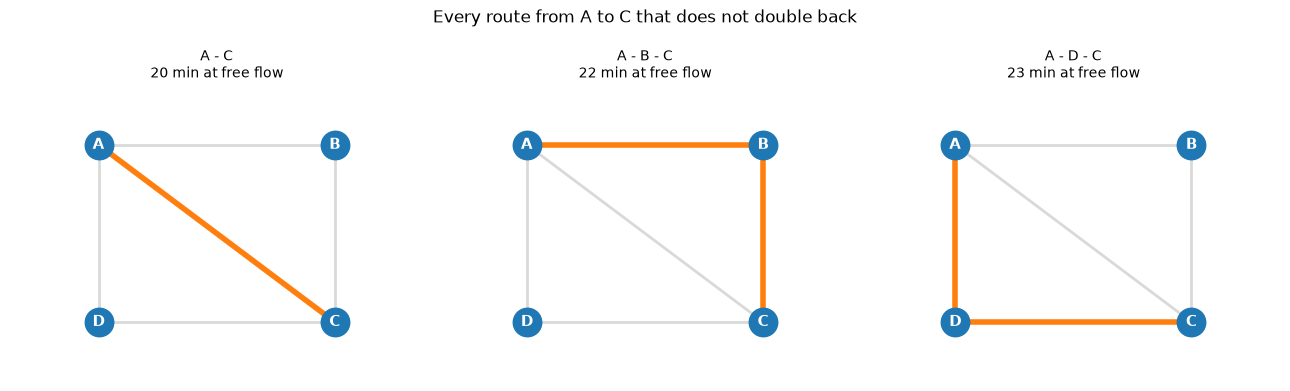

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
for ax, (zones, used) in zip(axes, routes_ac):
    for k, row in links.iterrows():
        (x1, y1), (x2, y2) = POS[row["from"]], POS[row["to"]]
        on_route = k in used
        ax.plot([x1, x2], [y1, y2], color="tab:orange" if on_route else "0.85",
                linewidth=4 if on_route else 2, zorder=2 if on_route else 1,
                solid_capstyle="round")
    draw_nodes(ax, size=420, fontsize=11)
    ax.set_xlim(0.5, 7.5)
    ax.set_ylim(0.5, 5.5)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{' - '.join(zones)}\n{free_flow_total((zones, used))} min at free flow", fontsize=10)
fig.suptitle("Every route from A to C that does not double back")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

### Steps 2 and 3: loading the roads, and slowing them down

In [45]:
alpha, bpr_power = 0.15, 4
cap = links["capacity_vph"].to_numpy(dtype=float)
t0 = links["free_flow_min"].to_numpy(dtype=float)

def road_time(flow):
    """How long each road takes at a given flow (veh/h)."""
    return t0 * (1 + alpha * (flow / cap) ** bpr_power)

def all_or_nothing(demand, link_time):
    """Put each pair's vehicles on its quickest route. Returns the flow on each road."""
    flows = np.zeros(len(links))
    for (o, d), plist in paths.items():
        q = demand[idx[o], idx[d]]
        if q == 0:
            continue
        quickest = min(plist, key=lambda p: sum(link_time[k] for k in p[1]))
        for k in quickest[1]:
            flows[k] += q
    return flows

## Part K. Going round until it settles

**The circular problem.** Flows change the times, and times change the flows. You cannot solve one without the other.

**The fix.** Do not jump straight to the new answer: move only part of the way towards it, by a smaller step each time. Modellers call this the method of successive averages.

1. Work out the road times at the current flows.
2. Put everyone on their quickest route at those times. Call that target $y$.
3. Move part of the way: $x_{\text{new}} = x + \frac{1}{k}(y - x)$. The step $\frac{1}{k}$ shrinks each pass, so the flows settle.
4. Measure the **gap**: how much time everyone would save by switching to their quickest route.

$$\text{gap} = \frac{\sum_a x_a t_a - \sum_a y_a t_a}{\sum_a x_a t_a}$$

A gap near zero means nobody would gain by switching, which is what we want. We stop below 0.1%.

**TAG:** M3.1 Table 4, convergence below 0.1% — matches TAG. M3.1 §3.4 warns that this method can force the flows to look stable without really converging, which is why we test the gap rather than just watching the flows stop moving.

In [46]:
def msa(demand, tol=1e-3, max_iter=50):
    """Method of successive averages. Stops when the gap is below tol."""
    x = all_or_nothing(demand, t0)                 # first pass: free-flow times
    gaps = []
    for k in range(2, max_iter + 1):
        t = road_time(x)                            # times at the current flows
        y = all_or_nothing(demand, t)               # quickest routes at those times
        gap = (np.sum(x * t) - np.sum(y * t)) / np.sum(x * t)
        print(f"pass {k-1:2d}: gap {gap:.5f}   flows {x.round(0)}")
        gaps.append(gap)
        if gap < tol:
            break
        x = x + (y - x) / k                         # step size 1/k
    return x, gap, gaps

flows, final_gap, gap_history = msa(V_car, tol=1e-3)
print()
print("final gap:", round(final_gap, 5))

pass  1: gap 0.00000   flows [158. 110. 118.  84.  72.]

final gap: 0.0


In [47]:
t_final = road_time(flows)
links.assign(flow_vph=flows.round(0), time_min=t_final.round(2), v_over_c=(flows / cap).round(2))

,from,to,free_flow_min,capacity_vph,flow_vph,time_min,v_over_c
0,A,B,10,150,158.0,11.86,1.06
1,B,C,12,125,110.0,13.07,0.88
2,C,D,8,250,118.0,8.06,0.47
3,D,A,15,150,84.0,15.22,0.56
4,A,C,20,100,72.0,20.81,0.72


### Flows on the map

Left: everyone on their quickest route at free-flow times. Right: the flows after the loop settles.

**On these toy numbers the two are identical.** Every pair of zones has one clear quickest route, so nobody switches when the roads slow down, and the loop stops after one pass. Congestion still raises the times (see the curve below), it just does not move anyone. A different network or tighter capacities would be needed to show a switch.

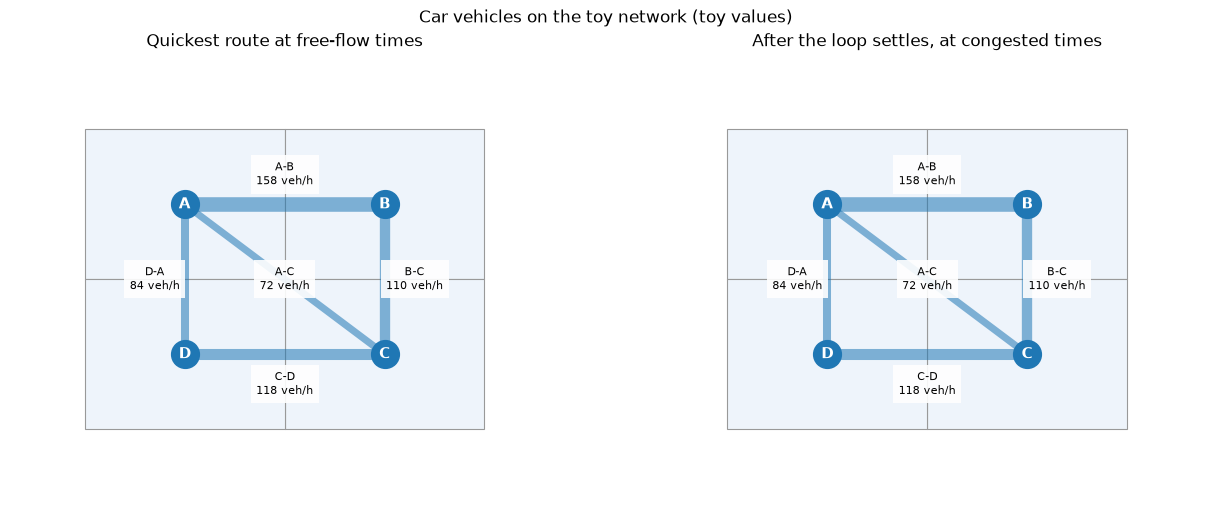

In [48]:
aon_flows = all_or_nothing(V_car, t0)
top_flow = max(aon_flows.max(), flows.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, f, title in [(axes[0], aon_flows, "Quickest route at free-flow times"),
                     (axes[1], flows, "After the loop settles, at congested times")]:
    for z, (x, y) in zone_corner.items():
        ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.6",
                               linewidth=0.8, zorder=0))
    for k, row in links.iterrows():
        (x1, y1), (x2, y2) = POS[row["from"]], POS[row["to"]]
        ax.plot([x1, x2], [y1, y2], color="tab:blue", alpha=0.55,
                linewidth=0.5 + 10 * f[k] / top_flow, solid_capstyle="round", zorder=2)
        mx, my = push_from_centre(x1, y1, x2, y2, by=0.6)
        ax.text(mx, my, f"{row['from']}-{row['to']}\n{f[k]:.0f} veh/h", ha="center", va="center",
                fontsize=8, zorder=4, bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
    draw_nodes(ax, size=400, fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-1.5, 9.5)
    ax.set_ylim(-1.5, 7.5)
    ax.axis("off")
    ax.set_title(title)
fig.suptitle("Car vehicles on the toy network (toy values)")
plt.tight_layout()
plt.show()

### How much slower a full road gets

The curve shows the slowdown as a road fills. The dots are our five roads at their final flows. Below about half capacity, almost nothing happens; past that it climbs fast.

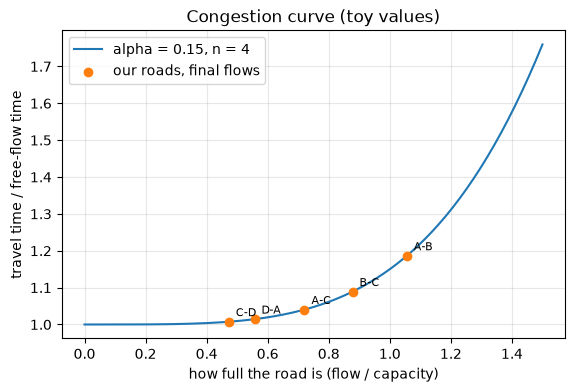

In [49]:
vc = np.linspace(0, 1.5, 200)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(vc, 1 + alpha * vc ** bpr_power, label=f"alpha = {alpha}, n = {bpr_power}")
ratio = t_final / t0
ax.scatter(flows / cap, ratio, color="tab:orange", zorder=3, label="our roads, final flows")
for k, row in links.iterrows():
    ax.annotate(f"{row['from']}-{row['to']}", (flows[k] / cap[k], ratio[k]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("how full the road is (flow / capacity)")
ax.set_ylabel("travel time / free-flow time")
ax.set_title("Congestion curve (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Level 6: checking the model

A model is only worth something if it matches something real. We compare it with counts and journey times it was **not** tuned to. Three checks:

1. **Road flows**, one road at a time, using GEH.
2. **Screenline**, the total crossing a line drawn across the area.
3. **Journey times** between pairs of zones.

The counts and times below are **made up**, for practice. In the plan they come from DfT counts and journey-time data.

**Why:** a model nobody has checked against real data cannot be trusted to forecast anything.

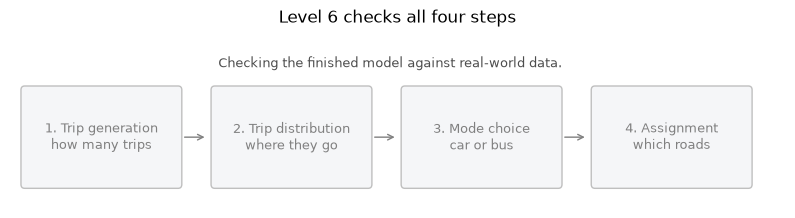

In [50]:
draw_stages(active=(), note="Checking the finished model against real-world data.",
            title="Level 6 checks all four steps")

## Part L. Road flows: GEH

**Question.** The model says 150 vehicles, the count says 130. Is that close enough?

It depends on the size of the road. Being 20 vehicles out matters a lot on a quiet lane and very little on a motorway. **GEH** builds that in by dividing by the average of the two:

$$\text{GEH} = \sqrt{\frac{2\,(M - C)^2}{M + C}}$$

where $M$ is the modelled flow and $C$ the counted one. Below 5 is a pass. The rule is that at least 85% of counted roads should pass; one bad road on its own is not a failure.

**This check fails here, on purpose.** The counts are made up, and the model was not tuned to hit them, so only 80% of the roads pass. The failure is left in because it shows what the check is for. Replace the counts with real ones before judging the model.

**TAG:** M3.1 Table 2, GEH below 5 on more than 85% of cases — matches TAG. M3.1 §3.3.11 also accepts an absolute or percentage test as an alternative; we use GEH alone, which is stricter.

In [51]:
def geh(M, C):
    return np.sqrt(2 * (M - C) ** 2 / (M + C))

# Made-up counts (veh/h), keyed by road so the order cannot go wrong.
# The A-C count is set well below the model, so this check fails on that road.
counted = {("A", "B"): 150.0, ("B", "C"): 130.0, ("C", "D"): 120.0,
           ("D", "A"): 106.0, ("A", "C"): 30.0}
counts = np.array([counted[(r["from"], r["to"])] for _, r in links.iterrows()])

check_links = links.assign(
    modelled=flows.round(0),
    counted=counts,
    geh=geh(flows, counts).round(2),
    geh_below_5=geh(flows, counts) < 5,
)
share_passing = check_links["geh_below_5"].mean()
print(f"roads with GEH below 5: {share_passing:.0%}   (need at least 85%)")
check_links

roads with GEH below 5: 80%   (need at least 85%)


,from,to,free_flow_min,capacity_vph,modelled,counted,geh,geh_below_5
0,A,B,10,150,158.0,150.0,0.67,True
1,B,C,12,125,110.0,130.0,1.85,True
2,C,D,8,250,118.0,120.0,0.16,True
3,D,A,15,150,84.0,106.0,2.31,True
4,A,C,20,100,72.0,30.0,5.89,False


## Part M. Screenlines and journey times

**Screenline.** Draw an imaginary line across the area and add up the flow on every road that crosses it. This tests the overall pattern of movement rather than any one road. Our line separates zones A and B from C and D. The total should be within 5%.

**Journey times.** For each pair of zones, compare the modelled time with an observed one. The rule: within 15%, or within 1 minute if that is more generous, on at least 85% of routes.

**TAG:** M2.2 §6.2.23, screenlines within ±5% for highway — matches TAG. M3.1 Table 3, journey times within 15% or 1 minute on more than 85% of routes — matches TAG.

In [52]:
# Roads crossing the line between {A, B} and {C, D}.
side_1 = {"A", "B"}
crossing = [k for k, r in links.iterrows() if (r["from"] in side_1) != (r["to"] in side_1)]
counted_screenline = counts[crossing].sum()
modelled_screenline = flows[crossing].sum()
screen_error = modelled_screenline / counted_screenline - 1

print(f"screenline: modelled {modelled_screenline:.0f} vs counted {counted_screenline:.0f}  "
      f"({screen_error:+.1%}, pass if within 5%)")

screenline: modelled 265 vs counted 266  (-0.3%, pass if within 5%)


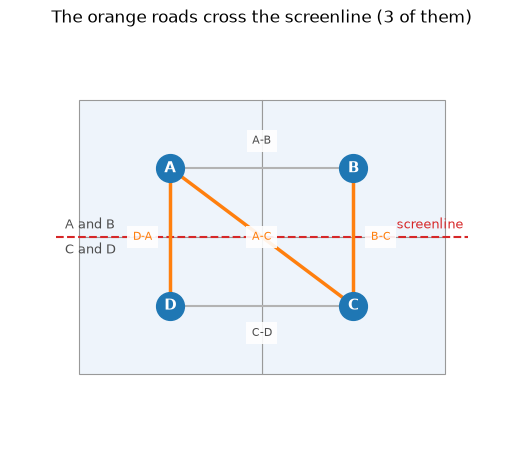

In [53]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for z, (x, y) in zone_corner.items():
    ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.6", linewidth=0.8, zorder=0))
for k, row in links.iterrows():
    (x1, y1), (x2, y2) = POS[row["from"]], POS[row["to"]]
    is_cross = k in crossing
    ax.plot([x1, x2], [y1, y2], color="tab:orange" if is_cross else "0.7",
            linewidth=2.5 if is_cross else 1.5, zorder=2)
    mx, my = push_from_centre(x1, y1, x2, y2, by=0.6)
    ax.text(mx, my, f"{row['from']}-{row['to']}", ha="center", va="center", fontsize=8, zorder=4,
            color="tab:orange" if is_cross else "0.3",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
draw_nodes(ax, size=400, fontsize=11)
ax.plot([-0.5, 8.5], [3, 3], color="tab:red", linestyle="--", linewidth=1.5, zorder=1)
ax.text(8.4, 3.12, "screenline", color="tab:red", fontsize=9, ha="right", va="bottom")
ax.text(-0.3, 3.12, "A and B", fontsize=9, color="0.3", ha="left", va="bottom")
ax.text(-0.3, 2.88, "C and D", fontsize=9, color="0.3", ha="left", va="top")
ax.set_aspect("equal")
ax.set_xlim(-1.5, 9.5)
ax.set_ylim(-1.5, 7.5)
ax.axis("off")
ax.set_title(f"The orange roads cross the screenline ({len(crossing)} of them)")
plt.show()

In [54]:
def min_path_time(o, d, link_time):
    """Quickest route time from zone o to zone d, at the given road times."""
    return min(sum(link_time[k] for k in p[1]) for p in paths[(o, d)])

# Made-up observed journey times (min) for three routes.
observed = {("A", "C"): 22.0, ("B", "D"): 24.0, ("C", "A"): 22.0}

journey = pd.DataFrame([
    {"route": f"{o} to {d}",
     "modelled": round(min_path_time(o, d, t_final), 1),
     "observed": obs,
     "within rule": abs(min_path_time(o, d, t_final) - obs) <= max(0.15 * obs, 1.0)}
    for (o, d), obs in observed.items()
])
journey

,route,modelled,observed,within rule
0,A to C,20.8,22.0,True
1,B to D,21.1,24.0,True
2,C to A,20.8,22.0,True


### The three checks as charts

**Left:** each dot is a road. Dots between the grey curves pass. **Middle:** the screenline total against the count, with the ±5% band. **Right:** journey times, with the allowed band.

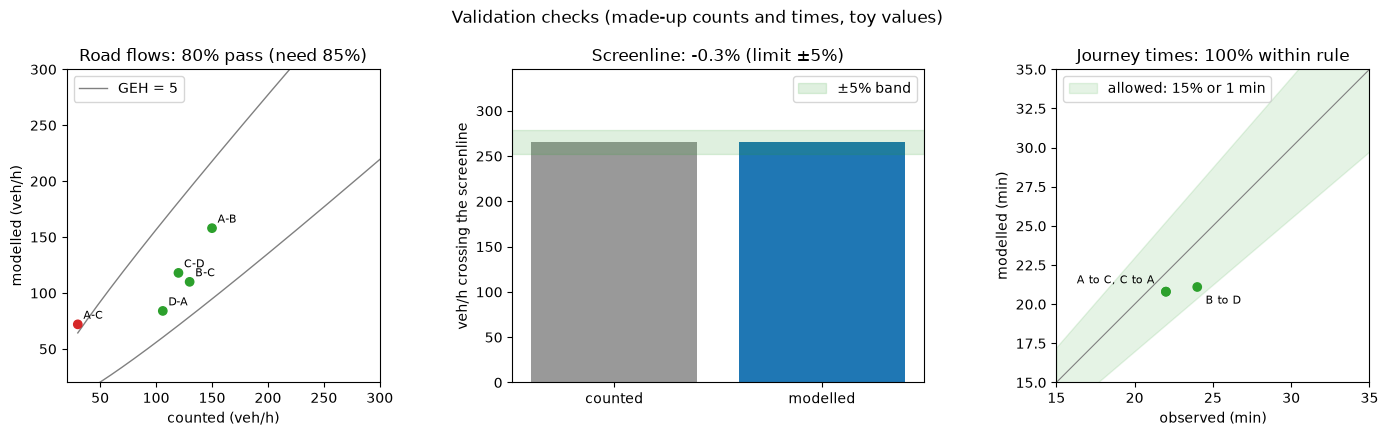

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# Left: GEH. The curves mark GEH = 5, from 2(M - C)^2 / (M + C) = 25.
ax = axes[0]
M = check_links["modelled"].to_numpy(float)
C = check_links["counted"].to_numpy(float)
Cl = np.linspace(30, 300, 200)
root = np.sqrt(625 + 400 * Cl)
ax.plot(Cl, Cl + (25 + root) / 4, color="0.5", linewidth=1)
ax.plot(Cl, Cl + (25 - root) / 4, color="0.5", linewidth=1, label="GEH = 5")
ax.scatter(C, M, c=np.where(check_links["geh_below_5"].to_numpy(), "tab:green", "tab:red"), zorder=3)
for k in range(len(links)):
    ax.annotate(f"{links.loc[k, 'from']}-{links.loc[k, 'to']}", (C[k], M[k]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlim(20, 300)
ax.set_ylim(20, 300)
ax.set_aspect("equal")
ax.set_xlabel("counted (veh/h)")
ax.set_ylabel("modelled (veh/h)")
ax.set_title(f"Road flows: {share_passing:.0%} pass (need 85%)")
ax.legend(loc="upper left")

# Middle: screenline total against the count.
ax = axes[1]
ax.bar(["counted", "modelled"], [counted_screenline, modelled_screenline], color=["0.6", "tab:blue"])
ax.axhspan(counted_screenline * 0.95, counted_screenline * 1.05, color="tab:green", alpha=0.15,
           label="±5% band")
ax.set_ylim(0, counted_screenline * 1.3)
ax.set_ylabel("veh/h crossing the screenline")
ax.set_title(f"Screenline: {screen_error:+.1%} (limit ±5%)")
ax.legend(loc="upper right")

# Right: journey times.
ax = axes[2]
obs = journey["observed"].to_numpy(float)
mod = journey["modelled"].to_numpy(float)
ax.scatter(obs, mod, c=np.where(journey["within rule"].to_numpy(bool), "tab:green", "tab:red"), zorder=3)
same_point = {}                                  # routes landing on the same dot share one label
for o, m, r in zip(obs, mod, journey["route"]):
    same_point.setdefault((o, m), []).append(r)
for (o, m), names in same_point.items():
    offset, align = ((6, -12), "left") if "B to D" in names else ((-8, 6), "right")
    ax.annotate(", ".join(names), (o, m), textcoords="offset points", xytext=offset,
                fontsize=8, ha=align)
xs = np.linspace(15, 35, 50)
allowed = np.maximum(0.15 * xs, 1.0)
ax.fill_between(xs, xs - allowed, xs + allowed, color="tab:green", alpha=0.12,
                label="allowed: 15% or 1 min")
ax.plot([15, 35], [15, 35], color="0.5", linewidth=0.8)
ax.set_xlim(15, 35)
ax.set_ylim(15, 35)
ax.set_aspect("equal")
ax.set_xlabel("observed (min)")
ax.set_ylabel("modelled (min)")
ax.set_title(f"Journey times: {journey['within rule'].mean():.0%} within rule")
ax.legend(loc="upper left")

fig.suptitle("Validation checks (made-up counts and times, toy values)")
plt.tight_layout()
plt.show()

## Part N. The checks in one table

In [56]:
pd.DataFrame(
    [
        ("Road flows (GEH below 5)", f"{share_passing:.0%} of roads", "at least 85%", share_passing >= 0.85),
        ("Screenline total", f"{screen_error:+.1%}", "within 5%", abs(screen_error) <= 0.05),
        ("Journey times", f"{journey['within rule'].mean():.0%} of routes", "at least 85%",
         journey["within rule"].mean() >= 0.85),
    ],
    columns=["check", "result", "rule", "passes"],
)

,check,result,rule,passes
0,Road flows (GEH below 5),80% of roads,at least 85%,False
1,Screenline total,-0.3%,within 5%,True
2,Journey times,100% of routes,at least 85%,True


### The notebook checks itself

These run on every pass and confirm the arithmetic holds together.

In [57]:
# Trip totals match their targets.
assert np.allclose(T_w.sum(axis=1), P_w, rtol=2e-3), "work row totals must equal productions"
assert np.allclose(T_w.sum(axis=0), A_w, rtol=2e-3), "work column totals must equal attractions"
assert np.allclose(T_o.sum(axis=1), P_o), "other row totals must equal productions"

# Every split adds back to the total.
assert np.allclose(T_own + T_zero, T_all), "car available + no car must equal all trips"
assert np.allclose(T_car_person + T_bus, T_all), "car + bus must equal all trips"

# Vehicles are people divided by occupancy, ignoring trips inside a zone.
assert np.isclose(V_car.sum(), (T_car_person.sum() - np.trace(T_car_person)) / occupancy), \
    "vehicles must equal car people / occupancy, off the diagonal"
assert np.all(flows >= 0), "road flows cannot be negative"

# The made-up data is set up to fail the GEH check only (see Part L).
assert share_passing < 0.85, "GEH should fail on the made-up counts, by design"
assert screen_error <= 0.05 and journey["within rule"].mean() >= 0.85, \
    "screenline and journey times should pass"
print("All checks passed.")

All checks passed.


# Appendix: finding the shortest times with an algorithm

Part A worked out the shortest times by hand, which only works because there are four zones. Real models use an algorithm. This one is **Floyd–Warshall**, and it is short enough to read in full.

**The idea.** Start with just the roads: a zone is 0 minutes from itself, and two zones with no road between them are infinitely far apart. Then take each zone $k$ in turn and ask, for every pair $(i, j)$: *is going via $k$ quicker than the best I know?* If so, keep it.

Why that is enough: any route either goes direct, or passes through some zone. Trying every zone as a stop-over covers both, so the table ends up holding the shortest times.

The cell below runs it and checks it agrees with the hand-written table in Part A.

In [58]:
computed = link_time.copy()
for k in range(n):
    for i in range(n):
        for j in range(n):
            if computed[i, k] + computed[k, j] < computed[i, j]:
                computed[i, j] = computed[i, k] + computed[k, j]

print(pd.DataFrame(computed, index=ZONES, columns=ZONES))
print()
assert np.allclose(computed, best), "the algorithm must agree with the hand-worked table in Part A"
print("The algorithm agrees with the table worked out by hand in Part A.")

      A     B     C     D
A   0.0  10.0  20.0  15.0
B  10.0   0.0  12.0  20.0
C  20.0  12.0   0.0   8.0
D  15.0  20.0   8.0   0.0

The algorithm agrees with the table worked out by hand in Part A.


## Notes

Write down anything that surprised you, and what you would check first if the numbers looked wrong.

Things to carry forward:

- Every placeholder above ($\beta$, $\lambda$, occupancy, value of time, fares, walk and wait weights, zero-car share, target car share, counts, journey times) is made up. Replace each with a sourced value and log it in `docs/methodology.md`.
- The bus penalty is fitted to a made-up car share, so its value means nothing until that target comes from data.
- Work and other trips share one set of costs, one $\lambda$ and one bus penalty. Shopping probably needs its own.
- The congestion curve is the BPR one, not the curve TAG specifies in M3.1 Appendix E.
- Congestion does not feed back into where trips go: distribution uses free-flow times only. That is the dashed red arrow in the Level 5 picture, and a possible later level.